# 22 Bestes Viertel als Maßstab, mit Lern- und Testprüfung

Teil 5: Anomalien und Monitoring

**Worum es geht**
- Der Netzvergleich (Notebook 19) misst jede Station am Median. Zeigt das beste Viertel je Kennzahl als zweiter Maßstab mehr, wenn schon die typische Station schlecht läuft?
- Hätte ein eingefrorener Maßstab, gelernt vor den Begehungen, die Stationen mit späterem Befund erkannt? Rücken begangene Stationen danach näher an die besten heran?
- Lücke = Abstand zum Median des besten Viertels, geteilt durch den Abstand der typischen Station (Median) dazu. 0 heißt so gut wie das beste Viertel, 1 so weit weg wie die typische Station.
- Potenzialwert = Mittel der Lücken über die Kennzahlen im Score. Stufen: unter 1 gering, 1 bis unter 2 mittel, ab 2 hoch (Setzung, vom Team zu bestätigen). Die Priorität bleibt, das Potenzial steht daneben.

**Daten**
- liest: Stundenreihen aus Notebook 00, Begehungstabelle mit kodierten Freitexten (über `src/stationsblatt.py`)
- schreibt: nichts
- vorher ausführen: Notebook 00

**Code**
- Logik in `src/netzvergleich.py` (`bestwert`, `grenzen_lernen`, `grenzen_anwenden`, `potenzial_je_winter`) und `src/stationsblatt.py`, Tests in `tests/test_netzvergleich.py` und `tests/test_stationsblatt.py`

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import befundcodes as bc
from src import netzvergleich as nv
from src import stationsblatt as bl

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

t0 = time.time()
e = bl.eingaben(ROOT)
erg = bl.rechne(e["serien"], e["termine"], e["anschlusswerte"], e["bhkw"],
                e["ohne_datum"], baujahr=e["baujahr"])
tab = erg["tabelle"]
kz = erg["kennzahlen"]
ref_aus = tuple(sorted(erg["bhkw"]))
termine = erg["termine"]
ohne_datum = erg["ohne_datum"]
labels = bc.labels_je_zaehler(bc.kodiere_begehungen())
befund = dict(zip(labels["meter"].astype(int), labels["n_befunde"] > 0))
print(f"{len(e['serien'])} Stundenreihen aus NB 00, gerechnet in "
      f"{time.time() - t0:.0f} s")
print("Kennzahlen im Score:", ", ".join(kz))
print("Stationen je Winter ohne BHKW:",
      tab[~tab["meter"].isin(ref_aus)].groupby("winter").size().to_dict())

93 Stundenreihen aus NB 00, gerechnet in 22 s
Kennzahlen im Score: spreizung_ref_k, steigung, residuum_sd, rl_ueber_50_anteil, flow_spez_lh_kw
Stationen je Winter ohne BHKW: {'22/23': 41, '23/24': 86, '24/25': 84, '25/26': 4}


## 1 Wie weit liegt die typische Station vom besten Viertel weg?

- Je Winter und Kennzahl: Median aller Stationen (ohne Stationen mit BHKW) und Median des besten Viertels.
- Hohe Werte sind gut bei Spreizung (Vorlauf minus Rücklauf) und Steigung.
- Niedrige Werte sind gut bei Streuung, Anteil Rücklauf über 50 °C und spezifischem Volumenstrom (l/h je kW Anschlusswert).

In [2]:
NAMEN = {k: v[0] for k, v in bl.LUECKE_EINHEIT.items()}
zeilen = []
for w in ["22/23", "23/24", "24/25"]:
    g = nv.grenzen_lernen(tab, kz, ref_aus, winter=[w])
    for k, r in g.iterrows():
        zeilen.append({"winter": w, "kennzahl": NAMEN.get(k, k),
                       "typisch": r["median"], "bestes_viertel": r["ziel"],
                       "n": int(r["n_werte"])})
ziele = pd.DataFrame(zeilen)
ziele.pivot(index="kennzahl", columns="winter",
            values=["typisch", "bestes_viertel"]).round(3)

typisch                 bestes_viertel                
winter         22/23   23/24   24/25          22/23   23/24   24/25
kennzahl                                                           
RL > 50 °C     0.453   0.354   0.292          0.049   0.047   0.032
Spreizung     22.932  25.688  25.648         33.264  33.326  34.654
Steigung       0.876   0.903   0.919          1.113   1.130   1.130
Streuung       0.284   0.232   0.224          0.146   0.148   0.126
Volumenstrom  14.774  13.617  14.625          7.562   7.231   7.500

- Winter 24/25: Spreizung typisch etwa 26 K, im besten Viertel etwa 35 K. Rücklauf über 50 °C typisch in knapp 30 % der Stunden, im besten Viertel in 3 %.
- Der spezifische Volumenstrom ist typisch rund doppelt so hoch wie im besten Viertel.
- Die Abstände sind über die drei Winter ähnlich.

## 2 Findet das beste Viertel andere Stationen als der Median-Score?

- Vergleich von Potenzialwert und bisherigem Score je Winter.
- Dazu: wie viele im Netzvergleich unauffällige Stationen haben trotzdem Potenzial hoch?

In [3]:
pot = erg["potenzial"]
mk = erg["markiert"]
m = mk.merge(pot[["meter", "winter", "potenzial", "potenzial_score",
                  "groesste_luecke"]
                 + [c for c in pot.columns if c.startswith("abstand_")]],
             on=["meter", "winter"], how="left")
m = m[m["score"].notna()]
print("Potenzial je Winter:")
display(pd.crosstab(m["winter"], m["potenzial"])[["gering", "mittel", "hoch"]])
rho = m.groupby("winter").apply(
    lambda g: stats.spearmanr(g["score"], g["potenzial_score"])[0])
print("Rangkorrelation Score gegen Potenzialwert:", rho.round(3).to_dict())
print("Rangbereich je Potenzialstufe im Winter 24/25:")
display(m[m["winter"] == "24/25"].groupby("potenzial")["rang"]
        .agg(["min", "max", "size"]))
print("Auffällig im Netzvergleich gegen Potenzial:")
display(pd.crosstab([m["winter"], m["auffaellig"]], m["potenzial"])
        [["gering", "mittel", "hoch"]])

Potenzial je Winter:


potenzial,gering,mittel,hoch
winter,,,
22/23,19,13,9
23/24,40,25,21
24/25,41,22,21


Rangkorrelation Score gegen Potenzialwert: {'22/23': 0.995, '23/24': 0.99, '24/25': 0.996}
Rangbereich je Potenzialstufe im Winter 24/25:


,min,max,size
potenzial,,,
gering,44.0,84.0,41
hoch,1.0,21.0,21
mittel,22.0,43.0,22


Auffällig im Netzvergleich gegen Potenzial:


potenzial          gering  mittel  hoch
winter auffaellig                      
22/23  False           19      13     3
       True             0       0     6
23/24  False           40      25    12
       True             0       0     9
24/25  False           41      22     9
       True             0       0    12

- Nein: die Rangkorrelation zum bisherigen Score liegt in allen Wintern bei 0,99 oder darüber. Beide sind Mittel über dieselben fünf Kennzahlen.
- Neu ist die Lesart: je Winter drei bis zwölf im Netzvergleich unauffällige Stationen mit Potenzial hoch.
- Lücken lassen sich in Einheiten ausdrücken, etwa „Spreizung 9 K unter dem besten Viertel“.

## 3 Priorität und Potenzial im Winter 24/25

- Kreuztabelle Priorität gegen Potenzialstufe.
- Liste der Stationen mit Potenzial hoch, die im Netzvergleich unauffällig sind.

In [4]:
prio = erg["prioritaet"]
w = m[m["winter"] == "24/25"].merge(prio[["meter", "winter", "prioritaet"]],
                                     on=["meter", "winter"], how="left")
display(pd.crosstab(w["prioritaet"], w["potenzial"])
        .reindex(index=["hoch", "mittel", "niedrig"],
                 columns=["gering", "mittel", "hoch"]).fillna(0).astype(int))
w["still_hoch"] = (w["potenzial"] == "hoch") & ~w["auffaellig"].astype(bool)
still = w[w["still_hoch"]].sort_values("potenzial_score", ascending=False)
still = still.assign(luecke=[
    bl.luecke_text(k, r[f"abstand_{k}"]) if isinstance(k, str) and k else ""
    for k, (_, r) in zip(still["groesste_luecke"], still.iterrows())])
print(f"{len(still)} Stationen mit Potenzial hoch, im Netzvergleich unauffällig:")
still[["meter", "rang", "n_schlecht", "prioritaet", "potenzial_score",
       "luecke"]].round(2).reset_index(drop=True)

potenzial,gering,mittel,hoch
prioritaet,,,
hoch,0,0,8
mittel,18,16,11
niedrig,23,6,2


9 Stationen mit Potenzial hoch, im Netzvergleich unauffällig:


,meter,rang,n_schlecht,prioritaet,potenzial_score,luecke
0,68956344,5.0,1,mittel,3.19,"Streuung 0,59 über dem besten Viertel"
1,68956356,9.0,1,niedrig,2.84,"Steigung 0,77 unter dem besten Viertel"
2,68956352,13.0,1,mittel,2.69,"Streuung 0,33 über dem besten Viertel"
3,72167782,16.0,1,niedrig,2.51,RL > 50 °C 96 Prozentpunkte über dem besten Vi...
4,80912172,17.0,1,mittel,2.51,"Volumenstrom 31,0 l/h je kW über dem besten Vi..."
5,72135440,18.0,0,mittel,2.48,"Volumenstrom 27,8 l/h je kW über dem besten Vi..."
6,72135478,19.0,1,mittel,2.27,"Streuung 0,47 über dem besten Viertel"
7,80912169,20.0,1,mittel,2.25,"Streuung 0,33 über dem besten Viertel"
8,68956348,21.0,1,mittel,2.04,"Volumenstrom 33,9 l/h je kW über dem besten Vi..."


- Alle acht Stationen mit Priorität hoch haben Potenzial hoch.
- Dreizehn haben Potenzial hoch ohne Priorität hoch, neun davon sind im Netzvergleich unauffällig.
- Streuung: Standardabweichung um die Kennlinie im logarithmischen Maßstab. 0,3 entspricht grob 30 % Abweichung beim Volumenstrom.
- Haben die neun etwas gemeinsam? Prüfung mit Fisher- bzw. Mann-Whitney-Test wie in Notebook 19.

In [5]:
kontext = nv.kontext_tabelle(sorted(tab["meter"].unique()),
                             erg["anschlusswerte"], erg["bhkw"], termine,
                             labels, begangen_ohne_datum=ohne_datum)
nv.profil(w, kontext, gruppe="still_hoch").head(8).round(3)

,merkmal,auspraegung,test,n_gruppe,n_rest,wert_gruppe,wert_rest,p_wert
0,regler_parameter,,fisher,7,45,0.429,0.067,0.026
1,baujahr,,mannwhitney,2,15,2014.500,1990.000,0.073
2,heizkoerper,,fisher,7,45,0.143,0.444,0.219
3,anschlusswert_kw,,mannwhitney,9,71,8.000,10.000,0.336
4,daemmung,,fisher,7,45,0.143,0.044,0.358
5,pumpe,,fisher,7,45,0.143,0.067,0.450
6,hat_begehung,,fisher,9,75,0.778,0.600,0.472
7,holzfeuerung,,fisher,7,45,0.143,0.089,0.530


- Kein Merkmal trennt die Gruppe.
- Am ehesten haben sie öfter Befunde zu Regler oder Parametern (drei von sieben begangenen gegen 7 % beim Rest). Nur ein Hinweis.

## 4 Eingefrorener Maßstab: lernen vor den Begehungen, testen danach

- Die Begehungen liegen fast alle zwischen August und November 2024. Lernwinter: 22/23 und 23/24, Testwinter: 24/25.
- Median, Streuung, Grenze für „schlecht“ und bestes Viertel kommen aus den Lernwintern und werden fest auf alle Winter angewendet.
- Begehungslabels gehen nicht ein.

In [6]:
grenzen = nv.grenzen_lernen(tab, kz, ref_aus, winter=["22/23", "23/24"])
print("Stationswinter im Lernzeitraum:", grenzen.attrs["n_referenz"])
display(grenzen.rename(index=NAMEN).round(3))
fest = nv.grenzen_anwenden(tab, grenzen)
fest = fest[~fest["meter"].isin(ref_aus)]
fest.groupby("winter").agg(stationen=("meter", "size"),
                           auffaellig=("auffaellig", "sum"),
                           potenzial_hoch=("potenzial", lambda s: (s == "hoch").sum()))

Stationswinter im Lernzeitraum: 127


,vorzeichen,median,skala,grenze_z,ziel,n_werte
kennzahl,,,,,,
Spreizung,-1,24.956,8.203,1.624,33.448,127
Steigung,-1,0.893,0.285,2.892,1.130,127
Streuung,1,0.241,0.120,2.505,0.147,127
RL > 50 °C,1,0.372,0.439,1.352,0.047,127
Volumenstrom,1,14.250,7.635,2.923,7.333,120


,stationen,auffaellig,potenzial_hoch
winter,,,
22/23,41,6,15
23/24,86,8,19
24/25,84,10,20
25/26,4,0,1


### 4.1 Vorher: waren die Stationen mit späterem Befund schon auffällig?

- Gruppen im Winter 23/24 nach dem späteren Ergebnis der Begehung.

In [7]:
erst = {mm: min(pd.Timestamp(x) for x in v) for mm, v in termine.items() if len(v)}


def vorher_gruppe(meter):
    if meter in erst or meter in ohne_datum:
        if meter not in befund:
            return "begangen, nicht kodiert"
        return "begangen mit Befund" if befund[meter] else "begangen ohne Befund"
    return "nie begangen"


def vorher_test(fest, winter="23/24"):
    v = fest[fest["winter"] == winter].copy()
    v["gruppe"] = v["meter"].map(vorher_gruppe)
    tabelle = v.groupby("gruppe").agg(
        n=("meter", "size"), anteil_auffaellig=("auffaellig", "mean"),
        anteil_potenzial_hoch=("potenzial", lambda s: (s == "hoch").mean()),
        potenzialwert_median=("potenzial_score", "median"))
    p = {}
    for spalte, wert in [("auffaellig", True), ("potenzial", "hoch")]:
        a = v.loc[v["gruppe"] == "begangen mit Befund", spalte] == wert
        b = v.loc[v["gruppe"] == "begangen ohne Befund", spalte] == wert
        p[spalte] = stats.fisher_exact([[a.sum(), (~a).sum()],
                                        [b.sum(), (~b).sum()]])[1]
    a = v.loc[v["gruppe"] == "begangen mit Befund", "potenzial_score"].dropna()
    b = v.loc[v["gruppe"] == "begangen ohne Befund", "potenzial_score"].dropna()
    p["potenzialwert"] = stats.mannwhitneyu(a, b)[1]
    return tabelle, p


tabelle_vor, p_vor = vorher_test(fest)
display(tabelle_vor.round(2))
print("p-Werte mit Befund gegen ohne Befund:",
      {k: round(v, 2) for k, v in p_vor.items()})

,n,anteil_auffaellig,anteil_potenzial_hoch,potenzialwert_median
gruppe,,,,
begangen mit Befund,28,0.11,0.25,1.14
begangen ohne Befund,26,0.04,0.15,1.01
nie begangen,32,0.12,0.25,0.96


p-Werte mit Befund gegen ohne Befund: {'auffaellig': np.float64(0.61), 'potenzial': np.float64(0.5), 'potenzialwert': np.float64(0.71)}


- Nicht erkannt: auffällig sind drei von 28 Stationen mit späterem Befund, eine von 26 begangenen ohne Befund und vier von 32 nie begangenen. Kein Unterschied ist annähernd signifikant.
- Viele Befunde (Schmutzfänger, Dämmung, Einstellungen) zeigen sich kaum in Spreizung oder Volumenstrom.
- „Ohne Befund“ heißt nur, dass nichts notiert wurde.

### 4.2 Nachher: rücken begangene Stationen näher an die besten heran?

- Änderung von Winter 23/24 nach 24/25.
- Begangen: erste Begehung August bis November 2024. Nicht begangen: keine datierte Begehung vor März 2025.

In [8]:
def nachher_gruppe(meter):
    if meter in ohne_datum:
        return None
    d = erst.get(meter)
    if d is None or d >= pd.Timestamp("2025-03-01"):
        return "nicht begangen"
    if pd.Timestamp("2024-08-01") <= d < pd.Timestamp("2024-12-01"):
        return "begangen Aug-Nov 24"
    return None


def nachher_test(fest):
    p = fest.pivot_table(index="meter", columns="winter",
                         values=["score", "potenzial_score", "auffaellig"],
                         aggfunc="first")
    p.columns = [f"{a}|{b}" for a, b in p.columns]
    p = p.dropna(subset=["score|23/24", "score|24/25"])
    p["gruppe"] = p.index.map(nachher_gruppe)
    p = p[p["gruppe"].notna()].copy()
    p["d_score"] = p["score|24/25"] - p["score|23/24"]
    p["d_potenzial"] = p["potenzial_score|24/25"] - p["potenzial_score|23/24"]
    p["befund"] = [befund.get(mm) for mm in p.index]
    b = p["gruppe"] == "begangen Aug-Nov 24"
    pw = {s: stats.mannwhitneyu(p.loc[b, s].dropna(), p.loc[~b, s].dropna())[1]
          for s in ["d_score", "d_potenzial"]}
    return p, pw


nach, p_nach = nachher_test(fest)
display(nach.groupby("gruppe")[["d_score", "d_potenzial"]]
        .agg(["median", "size"]).round(3))
print("Mann-Whitney begangen gegen nicht begangen:",
      {k: round(v, 2) for k, v in p_nach.items()})
print("Auffällig vorher (23/24) gegen nachher (24/25):")
display(pd.crosstab([nach["gruppe"], nach["auffaellig|23/24"].astype(bool)],
                    nach["auffaellig|24/25"].astype(bool)))
print("Nur begangene, nach Befund:")
nach[nach["gruppe"] == "begangen Aug-Nov 24"].groupby("befund")[
    "d_potenzial"].agg(["median", "size"]).round(3)

d_score      d_potenzial     
                     median size      median size
gruppe                                           
begangen Aug-Nov 24   0.021   41      -0.008   41
nicht begangen        0.048   33       0.008   33

Mann-Whitney begangen gegen nicht begangen: {'d_score': np.float64(0.66), 'd_potenzial': np.float64(0.77)}
Auffällig vorher (23/24) gegen nachher (24/25):


auffaellig|24/25                      False  True 
gruppe              auffaellig|23/24              
begangen Aug-Nov 24 False                36      2
                    True                  2      1
nicht begangen      False                27      2
                    True                  1      3

Nur begangene, nach Befund:


,median,size
befund,,
False,0.054,20
True,-0.093,21


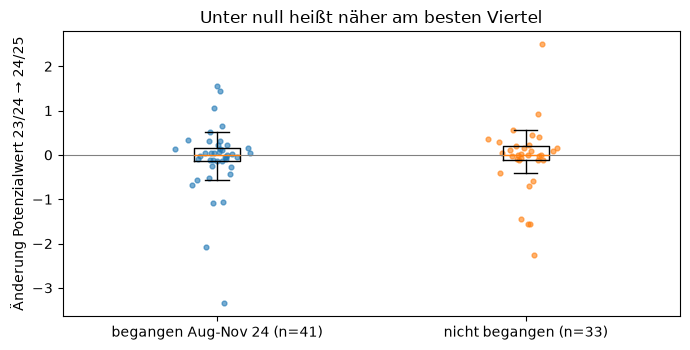

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.6))
gruppen = ["begangen Aug-Nov 24", "nicht begangen"]
daten = [nach.loc[nach["gruppe"] == g, "d_potenzial"].dropna() for g in gruppen]
ax.boxplot(daten, showfliers=False)
for i, d in enumerate(daten, start=1):
    ax.scatter(np.random.default_rng(i).normal(i, 0.05, len(d)), d, s=12,
               alpha=0.6, color="tab:blue" if i == 1 else "tab:orange")
ax.set_xticks([1, 2], [f"{g} (n={len(d)})" for g, d in zip(gruppen, daten)])
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Änderung Potenzialwert 23/24 → 24/25")
ax.set_title("Unter null heißt näher am besten Viertel")
fig.tight_layout()
plt.show()

- Kein Unterschied: der Potenzialwert ändert sich in beiden Gruppen im Median kaum.
- Vorher auffällige Stationen: von den begangenen sind zwei von drei danach unauffällig, von den nicht begangenen eine von vier. Nur eine Beobachtung.
- Passt zu Notebook 02 (Diff-in-Diff nicht signifikant, p um 0,4).

### 4.3 Gegenprobe: nur 22/23 als Lernwinter

- Oben ist 23/24 zugleich Lern- und Vorher-Winter.
- Deshalb zur Kontrolle nur 22/23 als Lernwinter (41 Stationen).

In [10]:
grenzen_alt = nv.grenzen_lernen(tab, kz, ref_aus, winter=["22/23"])
fest_alt = nv.grenzen_anwenden(tab, grenzen_alt)
fest_alt = fest_alt[~fest_alt["meter"].isin(ref_aus)]
print("Auffällig je Winter:",
      fest_alt.groupby("winter")["auffaellig"].sum().to_dict())
tabelle_alt, p_alt = vorher_test(fest_alt)
display(tabelle_alt.round(2))
print("Vorher, p-Werte:", {k: round(v, 2) for k, v in p_alt.items()})
nach_alt, p_nach_alt = nachher_test(fest_alt)
print("Nachher, p-Werte:", {k: round(v, 2) for k, v in p_nach_alt.items()})

Auffällig je Winter: {'22/23': 6, '23/24': 8, '24/25': 9, '25/26': 0}


,n,anteil_auffaellig,anteil_potenzial_hoch,potenzialwert_median
gruppe,,,,
begangen mit Befund,28,0.11,0.18,0.95
begangen ohne Befund,26,0.04,0.04,0.86
nie begangen,32,0.12,0.19,0.74


Vorher, p-Werte: {'auffaellig': np.float64(0.61), 'potenzial': np.float64(0.19), 'potenzialwert': np.float64(0.55)}
Nachher, p-Werte: {'d_score': np.float64(0.79), 'd_potenzial': np.float64(0.99)}


- Auffälligkeit unverändert.
- Beim Potenzial: 18 % gegen 4 % mit Potenzial hoch bei begangenen mit und ohne Befund (p = 0,19), nie begangene 19 %. Nur ein schwacher Hinweis.

## Zusammenfassung & Bewertung

**Ergebnis**
- Umgesetzt im Stationsblatt, in der Statustabelle (`potenzial`, `potenzial_score`, `groesste_luecke`, `bw_abstand_*`) und im Bericht von `python -m src.aktualisieren`. Die Priorität bleibt unverändert.
- Die typische Station liegt deutlich hinter den besten. Luft nach oben gibt es im ganzen Netz.

**Belastbar**
- Der Abstand der typischen Station zum besten Viertel, über drei Winter ähnlich.
- Die Rangfolge ändert sich kaum (Rangkorrelation 0,99). Neu sind Lücken in physikalischen Einheiten und eine weichere Stufe.

**Schwach**
- Der eingefrorene Maßstab sagt weder Befunde vorher, noch zeigt er eine Verbesserung nach den Begehungen.
- Bei etwa 50 begangenen Stationen und Labels aus Freitexten ist das kein Beleg gegen die Begehungen. Die Winterkennzahlen bilden die Befunde aber nicht ab.

**Offen**
- Stufengrenzen des Potenzials.
- Nachher-Test mit Winter 25/26, sobald Daten von mehr als vier Stationen vorliegen.